<a href="https://colab.research.google.com/github/prithvee2k4/Assesment_SL/blob/main/S_L_Assesment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Load Data

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('/content/drive/MyDrive/DSAB13/Datasets/bank_marketing_assessment_dataset.csv')

data.head()

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
0,69,retired,divorced,secondary,5467.0,no,no,unknown,nov,4,0,8,23029,no
1,21,admin,single,secondary,606.0,no,no,telephone,may,8,0,1,12000,no
2,27,technician,married,tertiary,-314.0,yes,no,cellular,nov,12,0,10,43597,no
3,53,management,single,secondary,1503.0,yes,yes,cellular,nov,6,0,10,24602,no
4,51,management,single,secondary,3037.0,no,no,unknown,jun,5,0,2,27127,no


# Dataset inspection

In [ ]:

print(data.shape)

print("\n")

print(data.columns)

print("\n")

data.info()

print("\n")

display(data.describe(include='all'))

# Missing values
print("missing values", data.isnull().sum())

print("\n")

# Duplicate records
print("duplicated records:", data.duplicated().sum())

(600, 14)


Index(['customer_age', 'job', 'marital_status', 'education', 'account_balance',
       'housing_loan', 'personal_loan', 'contact_type', 'contact_month',
       'campaign_contacts', 'previous_contacts', 'engagement_score',
       'annual_income_estimate', 'subscribed'],
      dtype='object')


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_age            600 non-null    int64  
 1   job                     600 non-null    object 
 2   marital_status          600 non-null    object 
 3   education               585 non-null    object 
 4   account_balance         588 non-null    float64
 5   housing_loan            600 non-null    object 
 6   personal_loan           600 non-null    object 
 7   contact_type            591 non-null    object 
 8   contact_month           600 non-null    object 
 9   c

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,subscribed
count,600.000000,600,600,585,588.000000,600,600,591,600,600.000000,600.000000,600.000000,600.0000,600
unique,NaN,6,3,3,NaN,2,2,3,6,NaN,NaN,NaN,NaN,2
top,NaN,admin,single,secondary,NaN,no,no,telephone,may,NaN,NaN,NaN,NaN,no
freq,NaN,232,361,295,NaN,454,407,231,120,NaN,NaN,NaN,NaN,426
mean,38.208333,NaN,NaN,NaN,1535.037415,NaN,NaN,NaN,NaN,5.566667,1.015000,4.451667,31805.3650,NaN
std,15.387426,NaN,NaN,NaN,2366.916896,NaN,NaN,NaN,NaN,2.020485,1.582914,2.938603,17264.0821,NaN
min,18.000000,NaN,NaN,NaN,-5418.000000,NaN,NaN,NaN,NaN,3.000000,0.000000,1.000000,12000.0000,NaN
25%,26.000000,NaN,NaN,NaN,-24.750000,NaN,NaN,NaN,NaN,4.000000,0.000000,1.000000,16112.5000,NaN
50%,34.000000,NaN,NaN,NaN,1589.500000,NaN,NaN,NaN,NaN,5.000000,0.000000,4.000000,29156.0000,NaN
75%,49.000000,NaN,NaN,NaN,3042.750000,NaN,NaN,NaN,NaN,7.000000,2.000000,7.000000,43444.0000,NaN


missing values customer_age               0
job                        0
marital_status             0
education                 15
account_balance           12
housing_loan               0
personal_loan              0
contact_type               9
contact_month              0
campaign_contacts          0
previous_contacts          0
engagement_score           0
annual_income_estimate     0
subscribed                 0
dtype: int64


duplicated records: 0


In [ ]:
# missing values


print("Missing Values:")
print(data.isnull().sum())

# total missing values
print("\nTotal Missing Values:", data.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Rows:", data.duplicated().sum())

Missing Values:
customer_age               0
job                        0
marital_status             0
education                 15
account_balance           12
housing_loan               0
personal_loan              0
contact_type               9
contact_month              0
campaign_contacts          0
previous_contacts          0
engagement_score           0
annual_income_estimate     0
subscribed                 0
dtype: int64

Total Missing Values: 36

Duplicate Rows: 0


Target variable

In [ ]:
# Count each target class
print(data["subscribed"].value_counts())

# Calculate percentage of each class
print("\nTarget Percentages:")
print(data["subscribed"].value_counts(normalize=True) * 100)

subscribed
no     426
yes    174
Name: count, dtype: int64

Target Percentages:
subscribed
no     71.0
yes    29.0
Name: proportion, dtype: float64


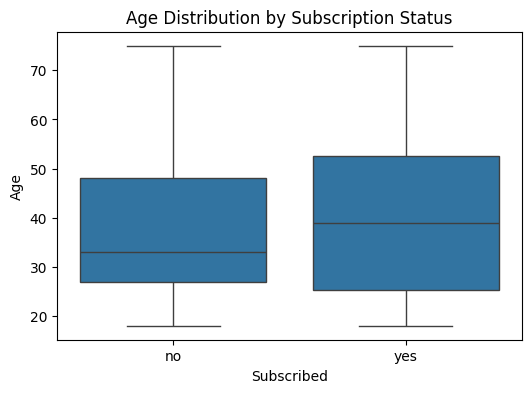

In [ ]:
#  boxplot visualization

plt.figure(figsize=(6, 4))

sns.boxplot(data=data, x="subscribed", y="customer_age")

plt.title("Age Distribution by Subscription Status")
plt.xlabel("Subscribed")
plt.ylabel("Age")

plt.show()


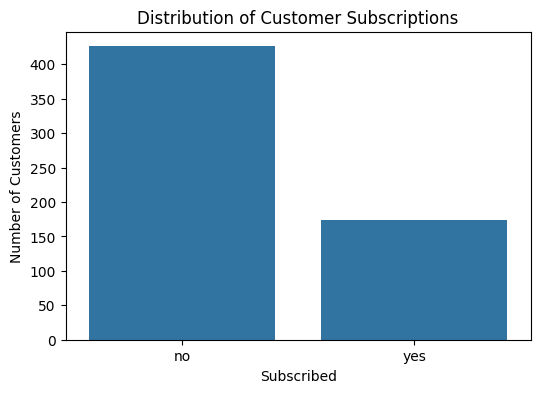

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=data, x="subscribed")

plt.title("Distribution of Customer Subscriptions")
plt.xlabel("Subscribed")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
# relationships between features/input and the target

# subscription percentage by loan status
loan_analysis = pd.crosstab(
    data["housing_loan"],
    data["subscribed"],
    normalize="index"
) * 100

print(loan_analysis)

print("\n")

# subscription percentage by account balance
balance_analysis = pd.crosstab(
    data["account_balance"],
    data["subscribed"],
    normalize="index"
) * 100

print(balance_analysis)

print("\n")

# subscription percentage by personal_loan
loan_analysis = pd.crosstab(
    data["personal_loan"],
    data["subscribed"],
    normalize="index"
) * 100

print(loan_analysis)

print("\n")

# campaign_contacts

subscribed           no        yes
housing_loan                      
no            79.295154  20.704846
yes           45.205479  54.794521


subscribed          no    yes
account_balance              
-5418.0          100.0    0.0
-5051.0          100.0    0.0
-5014.0            0.0  100.0
-4691.0            0.0  100.0
-4514.0          100.0    0.0
...                ...    ...
 7042.0          100.0    0.0
 7071.0          100.0    0.0
 7438.0          100.0    0.0
 8555.0            0.0  100.0
 9365.0            0.0  100.0

[570 rows x 2 columns]


subscribed            no        yes
personal_loan                      
no             85.012285  14.987715
yes            41.450777  58.549223




In [ ]:
# relationships between features/input and the target

# subscription percentage by loan status
loan_analysis = pd.crosstab(
    data["housing_loan"],
    data["subscribed"],
    normalize="index"
) * 100

print(loan_analysis)

print("\n")

# subscription percentage by account balance
balance_analysis = pd.crosstab(
    data["account_balance"],
    data["subscribed"],
    normalize="index"
) * 100

print(balance_analysis)

print("\n")

# subscription percentage by personal_loan
loan_analysis = pd.crosstab(
    data["personal_loan"],
    data["subscribed"],
    normalize="index"
) * 100

print(loan_analysis)

print("\n")

# subscription percentage by campaign_contacts
campaign_analysis = pd.crosstab(
    data["campaign_contacts"],
    data["subscribed"],
    normalize="index"
) * 100

print(campaign_analysis)

print("\n")

# subscription percentage by engagement_score
engagement_analysis = pd.crosstab(
    data["engagement_score"],
    data["subscribed"],
    normalize="index"
) * 100

print(engagement_analysis)

print("\n")

# subscription percentage by annual_income_estimate
income_analysis = pd.crosstab(
    data["annual_income_estimate"],
    data["subscribed"],
    normalize="index"
) * 100

print(income_analysis)

print("\n")

subscribed           no        yes
housing_loan                      
no            79.295154  20.704846
yes           45.205479  54.794521


subscribed          no    yes
account_balance              
-5418.0          100.0    0.0
-5051.0          100.0    0.0
-5014.0            0.0  100.0
-4691.0            0.0  100.0
-4514.0          100.0    0.0
...                ...    ...
 7042.0          100.0    0.0
 7071.0          100.0    0.0
 7438.0          100.0    0.0
 8555.0            0.0  100.0
 9365.0            0.0  100.0

[570 rows x 2 columns]


subscribed            no        yes
personal_loan                      
no             85.012285  14.987715
yes            41.450777  58.549223


subscribed                no         yes
campaign_contacts                       
3                  81.012658   18.987342
4                  76.978417   23.021583
5                  71.666667   28.333333
6                  73.626374   26.373626
7                  69.014085   30.985915
8        

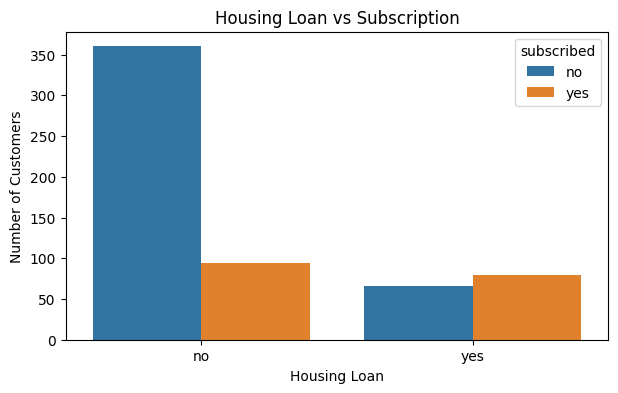

In [ ]:
# visualizations

plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    x="housing_loan",
    hue="subscribed"
)

plt.title("Housing Loan vs Subscription")
plt.xlabel("Housing Loan")
plt.ylabel("Number of Customers")

plt.show()

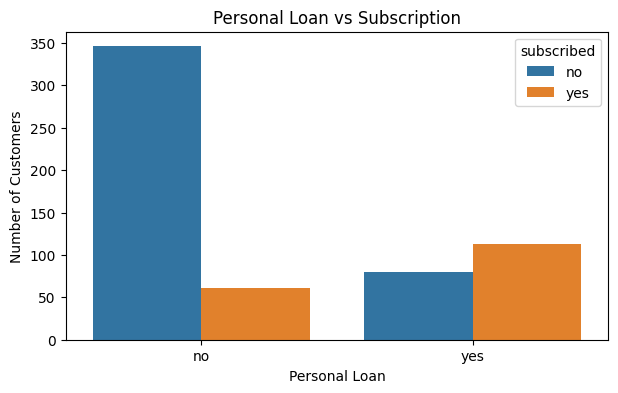

In [ ]:
# personal loans
plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    x="personal_loan",
    hue="subscribed"
)

plt.title("Personal Loan vs Subscription")
plt.xlabel("Personal Loan")
plt.ylabel("Number of Customers")

plt.show()

Data preparation and feature engineering

In [ ]:
# Separate X and y
# Separate input features (X)
X = data.drop("subscribed", axis=1)

# Separate target variable (y)
y = data["subscribed"]

# Display input features
print("Input Features:")
print(X.head())

print("\n")

# Display target variable
print("Target Variable:")
print(y.head())

print("\n")

Input Features:
   customer_age         job marital_status  education  account_balance  \
0            69     retired       divorced  secondary           5467.0   
1            21       admin         single  secondary            606.0   
2            27  technician        married   tertiary           -314.0   
3            53  management         single  secondary           1503.0   
4            51  management         single  secondary           3037.0   

  housing_loan personal_loan contact_type contact_month  campaign_contacts  \
0           no            no      unknown           nov                  4   
1           no            no    telephone           may                  8   
2          yes            no     cellular           nov                 12   
3          yes           yes     cellular           nov                  6   
4           no            no      unknown           jun                  5   

   previous_contacts  engagement_score  annual_income_estimate  
0    

In [ ]:
# Train-test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)



X_train shape: (480, 13)
X_test shape: (120, 13)
y_train shape: (480,)
y_test shape: (120,)


In [ ]:
# Identify numerical and categorical columns
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['customer_age', 'account_balance', 'campaign_contacts', 'previous_contacts', 'engagement_score', 'annual_income_estimate']

Categorical Features:
['job', 'marital_status', 'education', 'housing_loan', 'personal_loan', 'contact_type', 'contact_month']


In [ ]:
# preprocessing pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# preprocessing numerical values
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())
])

# preprocessing categorical values
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# combine both preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ])


print("Preprocessing pipeline created")


Preprocessing pipeline created


Build:
* Logistic Regression

* Random Forest Classifier

In [ ]:
# required algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Importing Pipeline
from sklearn.pipeline import Pipeline


In [ ]:
# Build the Logistic Regression pipeline

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Build the Random Forest pipeline

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
print(logistic_model)
print("\n")
print(random_forest_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['customer_age',
                                                   'account_balance',
                                                   'campaign_contacts',
                                                   'previous_contacts',
                                                   'engagement_score',
                                                   'annual_income_estimate']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                

In [ ]:
print("Logistic Regression model accuracy:", logistic_model.score(X_test, y_test))
print("Random Forest model accuracy:", random_forest_model.score(X_test, y_test))

Logistic Regression model accuracy: 0.85
Random Forest model accuracy: 0.8416666666666667


# Model Evaluation and Comparison

In [ ]:
# prediction using both models

y_pred_logistic = logistic_model.predict(X_test)
y_pred_random_forest = random_forest_model.predict(X_test)

print("Logistic Regression predictions:")
print(y_pred_logistic)

print("\n")

print("Random Forest predictions:")
print(y_pred_random_forest)


Logistic Regression predictions:
['no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no'
 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes'
 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no'
 'no' 'no' 'no' 'yes' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'yes' 'no'
 'yes' 'no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no']


Random Forest predictions:
['no' 'yes' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no'
 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'yes' 'no'
 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'yes' 'no' 'no' 'no' 'no' 'no' 'yes'
 'no' 'no' 

In [ ]:
# calculate evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


Logistic Regression

In [ ]:
print("LOGISTIC REGRESSION")

print("Accuracy:", accuracy_score(y_test, y_pred_logistic))

print("Precision:", precision_score(
    y_test, y_pred_logistic, pos_label="yes"
))

print("Recall:", recall_score(
    y_test, y_pred_logistic, pos_label="yes"
))

print("F1 Score:", f1_score(
    y_test, y_pred_logistic, pos_label="yes"
))

LOGISTIC REGRESSION
Accuracy: 0.85
Precision: 0.8695652173913043
Recall: 0.5714285714285714
F1 Score: 0.6896551724137931


Random Forest

In [ ]:
print("RANDOM FOREST")

print("Accuracy:", accuracy_score(y_test, y_pred_random_forest))

print("Precision:", precision_score(
    y_test, y_pred_random_forest, pos_label="yes"
))

print("Recall:", recall_score(
    y_test, y_pred_random_forest, pos_label="yes"
))

print("F1 Score:", f1_score(
    y_test, y_pred_random_forest, pos_label="yes"
))

RANDOM FOREST
Accuracy: 0.8416666666666667
Precision: 0.8076923076923077
Recall: 0.6
F1 Score: 0.6885245901639344


Confusion Matrices

In [ ]:
# Confusion Matrices

from sklearn.metrics import confusion_matrix

# Logistic Regression
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

# Random Forest
cm_random_forest = confusion_matrix(y_test, y_pred_random_forest)

print("Logistic Regression Confusion Matrix:")
print(cm_logistic)

print("\n")

print("Random Forest Confusion Matrix:")
print(cm_random_forest)



Logistic Regression Confusion Matrix:
[[82  3]
 [15 20]]


Random Forest Confusion Matrix:
[[80  5]
 [14 21]]


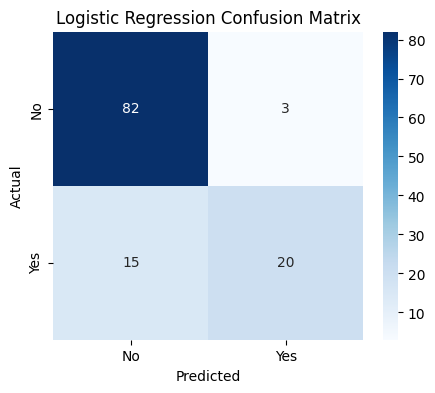

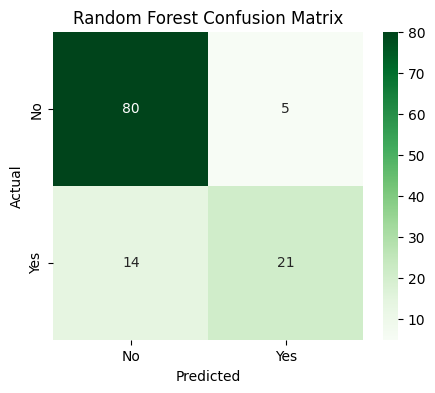

In [ ]:
# visualization
# Import visualization library
import matplotlib.pyplot as plt
import seaborn as sns

# Logistic Regression Confusion Matrix
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# Random Forest Confusion Matrix
plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_random_forest,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Classification Report

In [ ]:
# Classification Report

print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_logistic))

print("\n")

print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_random_forest))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

          no       0.85      0.96      0.90        85
         yes       0.87      0.57      0.69        35

    accuracy                           0.85       120
   macro avg       0.86      0.77      0.80       120
weighted avg       0.85      0.85      0.84       120



Random Forest Classification Report:
              precision    recall  f1-score   support

          no       0.85      0.94      0.89        85
         yes       0.81      0.60      0.69        35

    accuracy                           0.84       120
   macro avg       0.83      0.77      0.79       120
weighted avg       0.84      0.84      0.83       120



# Business Interpretation and Prediction

In [ ]:
# identify customer features that influence model prediction

# Get feature names after preprocessing
feature_names = random_forest_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance values
importance_values = random_forest_model.named_steps[
    "classifier"
].feature_importances_

# Create feature importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 10 features
feature_importance.head(10)

,Feature,Importance
0,num__customer_age,0.129833
5,num__annual_income_estimate,0.093997
21,cat__personal_loan_yes,0.089840
20,cat__personal_loan_no,0.088423
1,num__account_balance,0.079113
3,num__previous_contacts,0.076809
4,num__engagement_score,0.060401
2,num__campaign_contacts,0.050096
19,cat__housing_loan_yes,0.037020
18,cat__housing_loan_no,0.036216


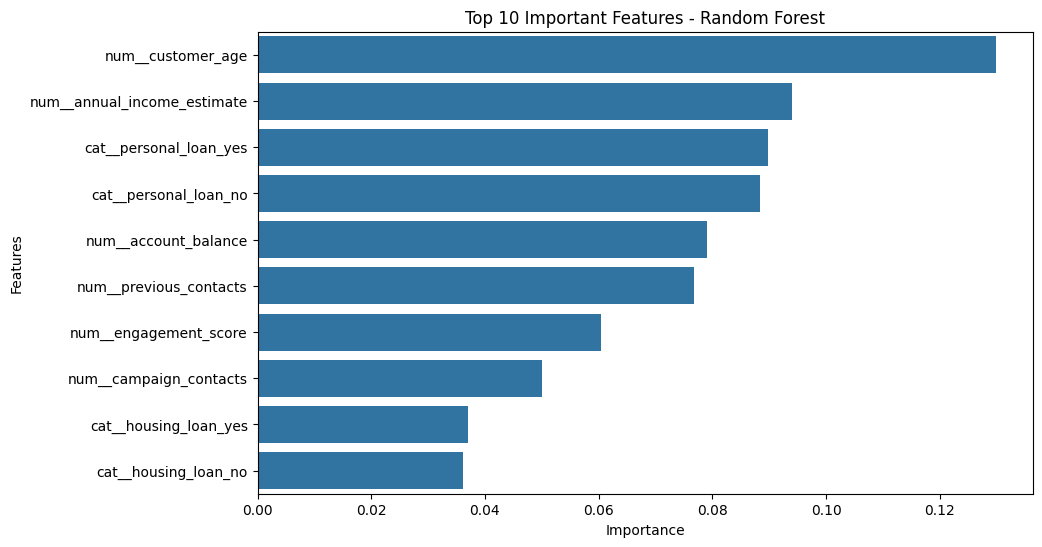

In [ ]:
# visualization

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.show()

Predict subscription

In [ ]:
# Predict subscription for five test customers

# Select five test customers
five_customers = X_test.iloc[:5]

# Predict subscription class
predictions = random_forest_model.predict(five_customers)

# Predict subscription probabilities
probabilities = random_forest_model.predict_proba(five_customers)

# Find the probability column corresponding to "yes"
yes_index = list(random_forest_model.classes_).index("yes")

# Extract subscription probabilities
yes_probabilities = probabilities[:, yes_index]

# Create prediction DataFrame
prediction_results = five_customers.copy()

prediction_results["Predicted_Subscription"] = predictions

prediction_results["Subscription_Probability"] = yes_probabilities

prediction_results

,customer_age,job,marital_status,education,account_balance,housing_loan,personal_loan,contact_type,contact_month,campaign_contacts,previous_contacts,engagement_score,annual_income_estimate,Predicted_Subscription,Subscription_Probability
269,54,blue-collar,single,tertiary,465.0,yes,no,telephone,nov,7,2,10,47415,no,0.16
70,18,admin,married,primary,-2078.0,yes,yes,unknown,aug,5,0,5,59372,yes,0.86
376,57,management,single,secondary,3482.0,no,no,unknown,nov,7,7,8,21463,no,0.22
543,64,services,single,secondary,3518.0,no,yes,telephone,may,9,0,1,12000,yes,0.77
429,23,admin,single,secondary,2332.0,no,no,unknown,may,6,0,1,19428,no,0.02


In [ ]:
# Select first 5 test customers
five_customers = X_test.iloc[:5]

# Predict subscription
predictions = random_forest_model.predict(five_customers)

# Predict probabilities
probabilities = random_forest_model.predict_proba(five_customers)

# Display results
for i in range(5):
    print("Customer", i+1)
    print("Predicted Subscription:", predictions[i])
    print("Probability of Yes:", probabilities[i][1])
    print()

Customer 1
Predicted Subscription: no
Probability of Yes: 0.16

Customer 2
Predicted Subscription: yes
Probability of Yes: 0.86

Customer 3
Predicted Subscription: no
Probability of Yes: 0.22

Customer 4
Predicted Subscription: yes
Probability of Yes: 0.77

Customer 5
Predicted Subscription: no
Probability of Yes: 0.02



 # **business conclusion**



I have built two classification models, Logistic Regression and Random Forest, to predict whether customers will subscribe to a term deposit.

Logistic Regression achieved 85% accuracy, while Random Forest achieved 84.17% accuracy. Logistic Regression performed better in precision, whereas Random Forest performed better in recall.

Since the bank wants to identify more potential subscribers, Random Forest can be a better choice. In the future, model performance can be improved by using more data and hyperparameter tuning.